<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== TRAINING DATASET ==========


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa



Total Samples: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']

Training Samples: 120
Testing Samples: 30

========== MODEL TRAINING COMPLETED ==========
Algorithm: Gaussian Naive Bayes

========== PREDICTION RESULTS ==========


,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


Testing Accuracy: 96.67 %

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


========== CONFUSION MATRIX ==========
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


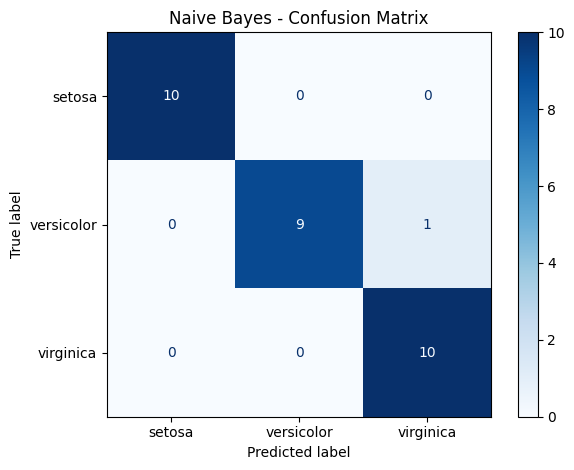

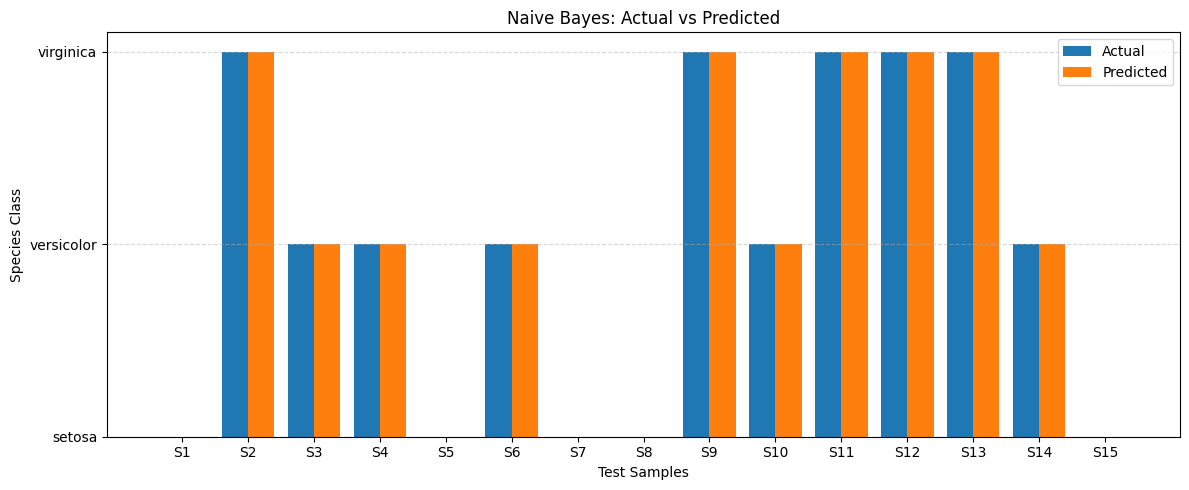

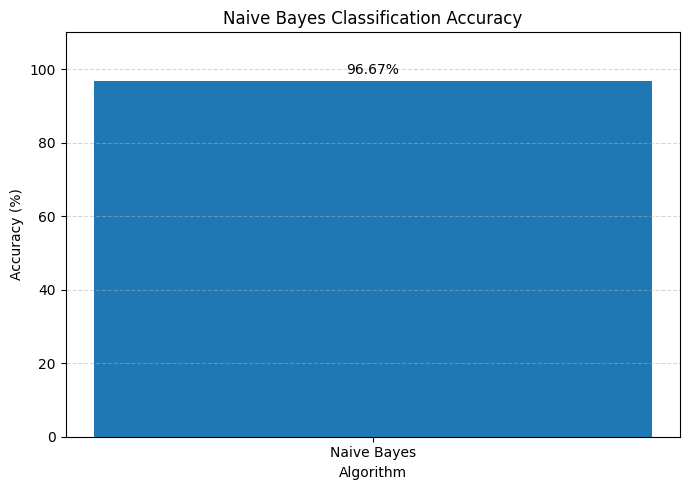


========== NEW SAMPLE PREDICTION ==========
Input Features: [5.1 3.5 1.4 0.2]
Predicted Species: setosa

Prediction Probabilities:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%

========== RESULT ==========
Naive Bayes Algorithm Executed Successfully.
Testing Accuracy: 96.67 %
Confusion Matrix Generated Successfully.


In [1]:
# EXPERIMENT 6: NAIVE BAYES CLASSIFICATION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# STEP 1: LOAD DATASET
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = iris.target_names[y]

print("========== TRAINING DATASET ==========")
display(df.head(10))

print("\nTotal Samples:", len(df))
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)

# STEP 2: SPLIT DATASET
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 3: CREATE NAIVE BAYES MODEL
model = GaussianNB()

# STEP 4: TRAIN MODEL
model.fit(X_train, y_train)

print("\n========== MODEL TRAINING COMPLETED ==========")
print("Algorithm: Gaussian Naive Bayes")

# STEP 5: PREDICT TEST DATA
y_pred = model.predict(X_test)

# STEP 6: CALCULATE ACCURACY
accuracy = accuracy_score(y_test, y_pred)

print("\n========== PREDICTION RESULTS ==========")

results = pd.DataFrame({
    'Actual Species': iris.target_names[y_test],
    'Predicted Species': iris.target_names[y_pred]
})

display(results)

print("Testing Accuracy:", round(accuracy * 100, 2), "%")

# STEP 7: CLASSIFICATION REPORT
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# STEP 8: CONFUSION MATRIX
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

print("\n========== CONFUSION MATRIX ==========")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.show()

# STEP 9: ACTUAL VS PREDICTED BAR GRAPH
sample_count = min(15, len(y_test))
sample_index = np.arange(sample_count)

plt.figure(figsize=(12, 5))

plt.bar(
    sample_index - 0.2,
    y_test[:sample_count],
    width=0.4,
    label='Actual'
)

plt.bar(
    sample_index + 0.2,
    y_pred[:sample_count],
    width=0.4,
    label='Predicted'
)

plt.title("Naive Bayes: Actual vs Predicted")
plt.xlabel("Test Samples")
plt.ylabel("Species Class")

plt.xticks(
    sample_index,
    [f'S{i+1}' for i in sample_index]
)

plt.yticks([0, 1, 2], iris.target_names)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 10: ACCURACY BAR GRAPH
plt.figure(figsize=(7, 5))

plt.bar(
    ['Naive Bayes'],
    [accuracy * 100]
)

plt.title("Naive Bayes Classification Accuracy")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)

plt.text(
    0,
    accuracy * 100 + 2,
    f'{accuracy * 100:.2f}%',
    ha='center'
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 11: TEST A NEW SAMPLE
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])

prediction = model.predict(new_sample)
probabilities = model.predict_proba(new_sample)

print("\n========== NEW SAMPLE PREDICTION ==========")
print("Input Features:", new_sample[0])
print("Predicted Species:", iris.target_names[prediction[0]])

print("\nPrediction Probabilities:")

for species, probability in zip(
    iris.target_names,
    probabilities[0]
):
    print(f"{species}: {probability * 100:.2f}%")

# STEP 12: FINAL RESULT
print("\n========== RESULT ==========")
print("Naive Bayes Algorithm Executed Successfully.")
print("Testing Accuracy:", round(accuracy * 100, 2), "%")
print("Confusion Matrix Generated Successfully.")